# Lab 05 : Détection d'objets dans une image avec YOLO

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/atouammi/Formation_CNN_API_Docker_Module4/blob/main/Labs/05_yolo_image_detection_example.ipynb)

Ce notebook montre comment détecter des objets dans une image avec YOLO et la bibliothèque Ultralytics. Il est conçu pour l'environnement JupyterLab de formation avec GPU, mais il fonctionne aussi sur CPU pour de petites images.

## Objectifs pédagogiques

À la fin de ce notebook, vous saurez :

- Comprendre ce que renvoie une détection d'objets YOLO.
- Charger un modèle YOLO pré-entraîné.
- Lancer une détection sur une image.
- Afficher les boîtes englobantes et les scores de confiance.
- Filtrer les détections par confiance et par classe.
- Remplacer l'image d'exemple par votre propre image.

Vous comprendrez ainsi le processus d'inférence de YOLO, la structure des résultats de détection, le rôle du seuil de confiance et les méthodes de visualisation.

## Prérequis d'environnement

- **En local (VS Code)** : Ultralytics est installé avec le reste du cours via `requirements.txt`.
- **Sur Google Colab** : la cellule de configuration ci-dessous installe Ultralytics automatiquement. Activez le GPU pour accélérer l'inférence : **Exécution → Modifier le type d'exécution → GPU (T4)**.

Sans GPU, le notebook fonctionne quand même sur CPU : l'inférence est simplement plus lente.

In [1]:
# ⚙️ Configuration – exécutez cette cellule en premier.
# - Sur Google Colab : récupère les fichiers du cours (plotting_utils/, assets/, requirements.txt)
#   et installe ce qui manque.
# - En local (VS Code) : rien à faire, l'environnement est déjà installé avec requirements.txt.
import os, sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO_DIR = "/content/Formation_CNN_API_Docker_Module4"
    if not os.path.exists(REPO_DIR):
        !git clone -q https://github.com/atouammi/Formation_CNN_API_Docker_Module4.git {REPO_DIR}
    %cd {REPO_DIR}/Labs
    %pip install -q ultralytics~=8.3.0

if "." not in sys.path:
    sys.path.append(".")
print("Environnement :", "Google Colab" if IN_COLAB else "local")

Environnement : local


In [2]:
import sys
import importlib.util

required = ["ultralytics", "torch", "cv2", "PIL", "matplotlib", "numpy"]
print("Python :", sys.version)
for name in required:
    print(f"{name:12s}", "installé" if importlib.util.find_spec(name) else "manquant")

Python : 3.12.1 (v3.12.1:2305ca5144, Dec  7 2023, 17:23:38) [Clang 13.0.0 (clang-1300.0.29.30)]
ultralytics  installé
torch        installé
cv2          installé
PIL          installé
matplotlib   installé
numpy        installé


In [3]:
import torch

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Version de Torch :", torch.__version__)
print("CUDA disponible :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))
else:
    print("Utilisation du CPU. La démo fonctionne quand même, mais l'inférence sera plus lente.")

Version de Torch : 2.6.0
CUDA disponible : False
Utilisation du CPU. La démo fonctionne quand même, mais l'inférence sera plus lente.


## Étape 1 : préparer une image d'exemple

Le notebook utilise une image d'exemple publique d'Ultralytics, déjà présente dans `assets/`. Si elle est absente, il la télécharge. Si le réseau n'est pas disponible, déposez votre propre image dans ce dossier et modifiez IMAGE_PATH.

Taille de l'image : (810, 1080)


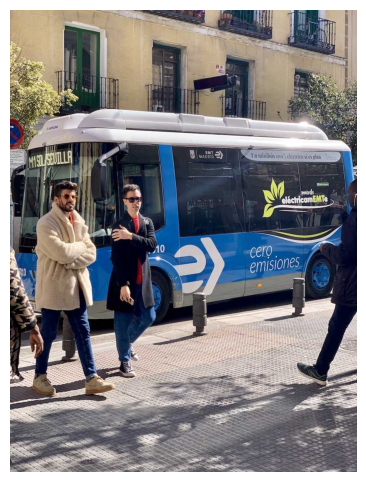

In [4]:
from pathlib import Path
from urllib.request import urlretrieve
from PIL import Image
import matplotlib.pyplot as plt

ASSET_DIR = Path("assets")
ASSET_DIR.mkdir(exist_ok=True)
IMAGE_PATH = ASSET_DIR / "yolo_bus.jpg"

if not IMAGE_PATH.exists():
    try:
        urlretrieve("https://ultralytics.com/images/bus.jpg", IMAGE_PATH)
        print("Image d'exemple téléchargée :", IMAGE_PATH)
    except Exception as exc:
        raise RuntimeError("Impossible de télécharger l'image d'exemple. Déposez votre propre image et indiquez son chemin dans IMAGE_PATH.") from exc

img = Image.open(IMAGE_PATH).convert("RGB")
print("Taille de l'image :", img.size)
plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.axis("off");

## Étape 2 : charger un modèle YOLO pré-entraîné

Nous utilisons yolov8n.pt, le petit modèle YOLOv8 « nano ». Il est rapide et adapté aux démonstrations en classe.

Lors de la première exécution, Ultralytics peut télécharger automatiquement le fichier de poids. Il est ensuite mis en cache dans le dossier courant ou dans le cache de l'utilisateur.

In [5]:
from ultralytics import YOLO

MODEL_NAME = "yolov8n.pt"
model = YOLO(MODEL_NAME)
print("Modèle chargé :", MODEL_NAME)

Modèle chargé : yolov8n.pt


## Étape 3 : lancer la détection

Paramètres importants :

- conf : seuil de confiance minimal.
- imgsz : taille de l'image utilisée pour l'inférence.
- device : identifiant du GPU (par exemple 0), ou "cpu".

Plus le seuil de confiance est élevé, plus les détections sont prudentes ; plus il est bas, plus il y a de détections, mais aussi de fausses détections.

In [6]:
results = model.predict(
    source=str(IMAGE_PATH),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    verbose=False,
)

result = results[0]
print("Nombre de détections :", len(result.boxes))

Nombre de détections : 5


## Étape 4 : visualiser les boîtes englobantes

Ultralytics peut dessiner automatiquement les boîtes, les étiquettes et les scores de confiance.

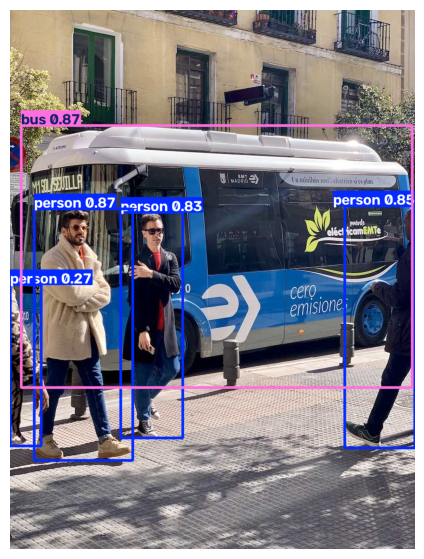

In [7]:
annotated_bgr = result.plot()
annotated_rgb = annotated_bgr[:, :, ::-1]

plt.figure(figsize=(10, 7))
plt.imshow(annotated_rgb)
plt.axis("off");

## Étape 5 : examiner les résultats de détection

Chaque détection comporte les coordonnées de sa boîte englobante, un score de confiance, un identifiant de classe et un nom de classe.

Ces résultats peuvent ensuite servir à compter des objets, déclencher une alerte, recadrer une cible, enregistrer un fichier JSON, alimenter une application métier, etc.

In [8]:
import pandas as pd

rows = []
for box in result.boxes:
    cls_id = int(box.cls[0])
    conf = float(box.conf[0])
    x1, y1, x2, y2 = [float(v) for v in box.xyxy[0]]
    rows.append({
        "class_id": cls_id,
        "class_name": result.names[cls_id],
        "confidence": round(conf, 3),
        "x1": round(x1, 1),
        "y1": round(y1, 1),
        "x2": round(x2, 1),
        "y2": round(y2, 1),
    })

df = pd.DataFrame(rows)
df

,class_id,class_name,confidence,x1,y1,x2,y2
0,5,bus,0.873,23.0,231.1,804.9,756.8
1,0,person,0.865,48.5,398.6,245.4,902.8
2,0,person,0.854,669.4,392.9,809.7,877.1
3,0,person,0.825,221.6,405.8,345.0,857.6
4,0,person,0.267,0.0,550.5,62.9,873.5


## Étape 6 : filtrer les résultats

Dans une application, on filtre généralement par confiance, par classe, par zone ou par taille d'objet. L'exemple ci-dessous ne garde que les personnes et les véhicules détectés avec une confiance élevée.

In [9]:
if df.empty:
    print("Aucune détection trouvée.")
else:
    target_classes = {"person", "car", "bus", "truck", "bicycle", "motorcycle"}
    filtered = df[(df["confidence"] >= 0.5) & (df["class_name"].isin(target_classes))]
    display(filtered)

,class_id,class_name,confidence,x1,y1,x2,y2
0,5,bus,0.873,23.0,231.1,804.9,756.8
1,0,person,0.865,48.5,398.6,245.4,902.8
2,0,person,0.854,669.4,392.9,809.7,877.1
3,0,person,0.825,221.6,405.8,345.0,857.6


## Étape 7 : utiliser votre propre image

Déposez une image dans ce dossier Jupyter, puis modifiez le chemin :

~~~python
IMAGE_PATH = Path("votre_image.jpg")
results = model.predict(source=str(IMAGE_PATH), conf=0.25, imgsz=640, device=DEVICE)
~~~

Formats conseillés : .jpg, .jpeg, .png. Si l'image est très grande, redimensionnez-la d'abord ou utilisez une valeur d'imgsz plus petite.

## Questions pour la discussion

- Que se passe-t-il si vous abaissez conf de 0,25 à 0,10 ?
- Quels faux positifs ou quels objets manqués observez-vous ?
- Quelles classes sont importantes pour votre propre cas d'usage ?
- Les résultats de détection doivent-ils déclencher une action automatique, ou faut-il d'abord une vérification humaine ?
- Quels enjeux de vie privée ou de sécurité apparaissent lorsqu'on détecte des personnes ou des véhicules ?

YOLO est utile, mais un système en production a besoin de contrôles de qualité des données, d'une surveillance, d'une analyse de l'impact sur la vie privée et d'une responsabilité humaine clairement définie.